# Classification Track — Ola & Uber Booking Outcome Prediction
### 23CSE301 Machine Learning — Capstone, Review 2 · Team 6 · *Gig Analytics Earnings*

**Team 6:** Harsha Vardhan · M Pranav · S Rahul Kumar (classification track)

**Dataset:** Ola & Uber Bookings (Kaggle) — cleaned 10,000-row sample
**Target:** `Booking_Status` — 4 classes: *Success, Canceled by Driver, Canceled by Customer, Driver Not Found*
**Features (no leakage):** `Booking_Value`, `hour` (numeric) · `Vehicle_Type`, `day_of_week` (categorical)
**Metrics:** Accuracy, weighted Precision / Recall / F1, ROC-AUC (one-vs-rest), confusion matrix, 5-fold CV

| Section | Content |
|---|---|
| A | Dataset audit & EDA |
| B | Preprocessing, stratified split, majority-class baseline |
| C | The 10 classification algorithms — Part A (1–5, Review 1) + **Part B (6–10, Review 2)**, one per cell |
| D | Hyperparameter tuning (GridSearchCV) — one per cell |
| E | Final comparison, confusion matrices, ROC, best-model selection, export |
| F | Imbalance experiment & conclusion |

> **Honest framing.** The outcome of a booking depends mostly on things this dataset does not contain (driver availability, surge, traffic). We therefore report every model **against the majority-class baseline** so that the numbers are not over-sold.

In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)

RANDOM_STATE = 42
palette = sns.color_palette("colorblind")
os.makedirs('../models', exist_ok=True)
os.makedirs('figures', exist_ok=True)

# every figure is also saved to notebooks/figures/
_fig_no = [0]
_orig_show = plt.show
def _show_and_save(*a, **k):
    for n in plt.get_fignums():
        _fig_no[0] += 1
        plt.figure(n).savefig(f'figures/clf_{_fig_no[0]:02d}.png', dpi=110, bbox_inches='tight')
    _orig_show(*a, **k)
plt.show = _show_and_save

## Section A — Dataset Audit & EDA

### A1. Loading and auditing the data

In [2]:
clf_raw = pd.read_csv('../data/bookings_classification_10k.csv')
print("Shape:", clf_raw.shape)
display(clf_raw.head())
display(clf_raw.dtypes.to_frame('dtype').T)
print("\nMissing values per column:"); print(clf_raw.isna().sum().to_string())
print("Duplicate rows:", clf_raw.duplicated().sum())
display(clf_raw.describe().T.round(2))

Shape: (10000, 5)


,Booking_Status,Vehicle_Type,Booking_Value,day_of_week,hour
0,Success,Prime SUV,502,Friday,4
1,Canceled by Customer,Prime Sedan,134,Tuesday,17
2,Canceled by Customer,Bike,145,Sunday,5
3,Canceled by Customer,Bike,369,Wednesday,7
4,Success,Auto,417,Wednesday,19


,Booking_Status,Vehicle_Type,Booking_Value,day_of_week,hour
dtype,str,str,int64,str,int64



Missing values per column:
Booking_Status    0
Vehicle_Type      0
Booking_Value     0
day_of_week       0
hour              0
Duplicate rows: 18


,count,mean,std,min,25%,50%,75%,max
Booking_Value,10000.0,533.07,517.29,100.0,238.0,381.0,584.0,2997.0
hour,10000.0,11.61,6.89,0.0,6.0,12.0,18.0,23.0


### A2. Target distribution — the class imbalance

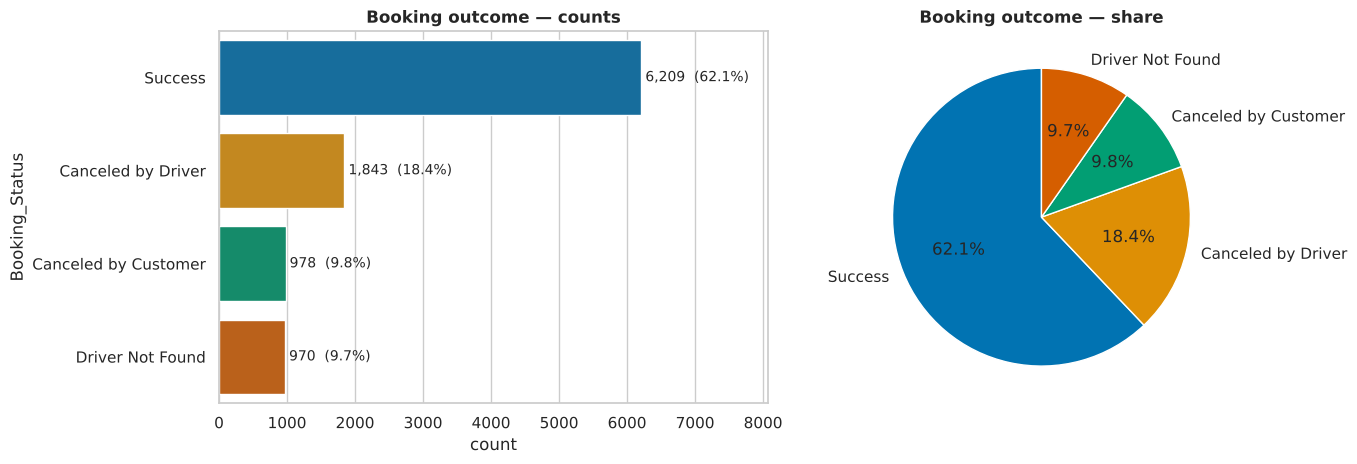

Majority class 'Success' = 62.1% of rows -> a model that always says 'Success' already scores 62.1% accuracy.


In [3]:
order = clf_raw['Booking_Status'].value_counts().index
counts = clf_raw['Booking_Status'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.countplot(data=clf_raw, y='Booking_Status', order=order, palette=palette, ax=axes[0])
for i, v in enumerate(counts[order]):
    axes[0].text(v + 60, i, f"{v:,}  ({v/len(clf_raw):.1%})", va='center', fontsize=10)
axes[0].set_title('Booking outcome — counts', fontweight='bold'); axes[0].set_xlim(0, counts.max()*1.3)
axes[1].pie(counts[order], labels=order, autopct='%1.1f%%', colors=palette[:4], startangle=90, wedgeprops={'edgecolor': 'white'})
axes[1].set_title('Booking outcome — share', fontweight='bold')
plt.tight_layout(); plt.show(); plt.close('all')
MAJ = counts.max() / len(clf_raw)
print(f"Majority class '{counts.idxmax()}' = {MAJ:.1%} of rows -> a model that always says '{counts.idxmax()}' already scores {MAJ:.1%} accuracy.")

### A3. Numeric features — distributions and relation to the outcome

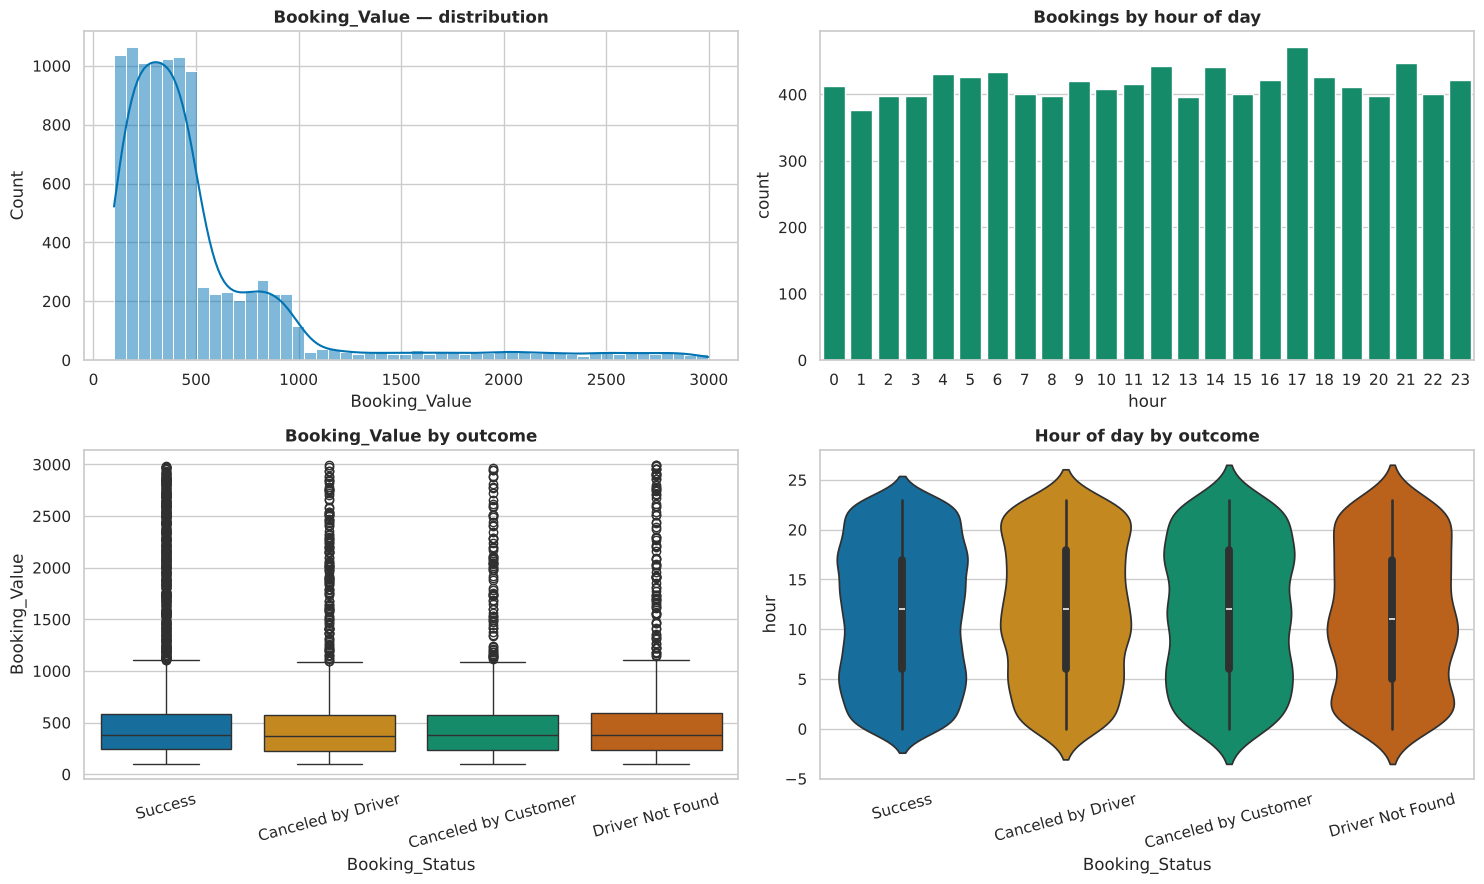

Booking_Value          hour       
                              mean median   mean median
Booking_Status                                         
Canceled by Customer        530.48  382.0  11.57   12.0
Canceled by Driver          516.31  375.0  11.86   12.0
Driver Not Found            557.25  384.0  11.38   11.0
Success                     534.68  382.0  11.57   12.0

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
sns.histplot(clf_raw['Booking_Value'], bins=50, kde=True, color=palette[0], ax=axes[0,0]); axes[0,0].set_title('Booking_Value — distribution', fontweight='bold')
sns.countplot(data=clf_raw, x='hour', color=palette[2], ax=axes[0,1]); axes[0,1].set_title('Bookings by hour of day', fontweight='bold')
sns.boxplot(data=clf_raw, x='Booking_Status', y='Booking_Value', order=order, palette=palette, ax=axes[1,0])
axes[1,0].set_title('Booking_Value by outcome', fontweight='bold'); axes[1,0].tick_params(axis='x', rotation=15)
sns.violinplot(data=clf_raw, x='Booking_Status', y='hour', order=order, palette=palette, ax=axes[1,1])
axes[1,1].set_title('Hour of day by outcome', fontweight='bold'); axes[1,1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show(); plt.close('all')
display(clf_raw.groupby('Booking_Status')[['Booking_Value', 'hour']].agg(['mean', 'median']).round(2))

### A4. Categorical features — outcome mix per vehicle type and weekday

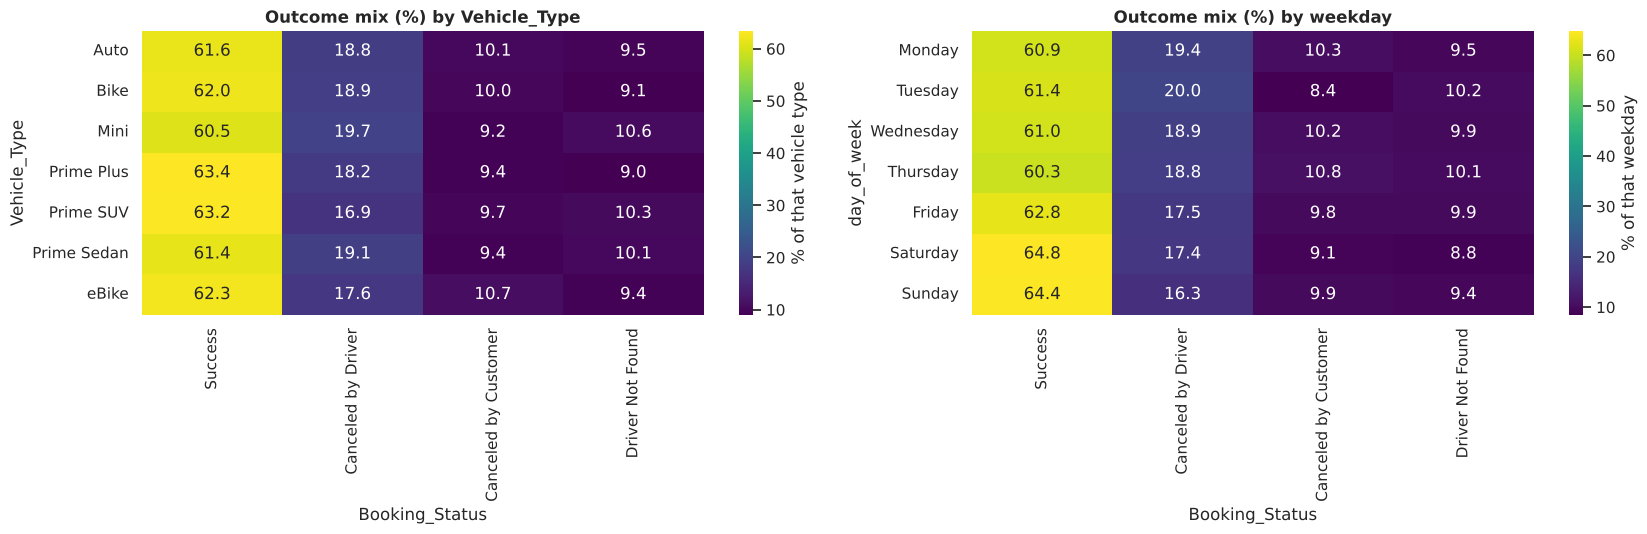

Spread of the 'Success' rate across vehicle types: 60.5% – 63.4%
Spread of the 'Success' rate across weekdays:      60.3% – 64.8%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
ct_v = pd.crosstab(clf_raw['Vehicle_Type'], clf_raw['Booking_Status'], normalize='index')[order] * 100
sns.heatmap(ct_v, annot=True, fmt='.1f', cmap='viridis', cbar_kws={'label': '% of that vehicle type'}, ax=axes[0])
axes[0].set_title('Outcome mix (%) by Vehicle_Type', fontweight='bold')
days = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
ct_d = (pd.crosstab(clf_raw['day_of_week'], clf_raw['Booking_Status'], normalize='index')[order] * 100).reindex(days)
sns.heatmap(ct_d, annot=True, fmt='.1f', cmap='viridis', cbar_kws={'label': '% of that weekday'}, ax=axes[1])
axes[1].set_title('Outcome mix (%) by weekday', fontweight='bold')
plt.tight_layout(); plt.show(); plt.close('all')
print("Spread of the 'Success' rate across vehicle types: %.1f%% – %.1f%%" % (ct_v['Success'].min(), ct_v['Success'].max()))
print("Spread of the 'Success' rate across weekdays:      %.1f%% – %.1f%%" % (ct_d['Success'].min(), ct_d['Success'].max()))

### A5. Correlation with the target (label-encoded)

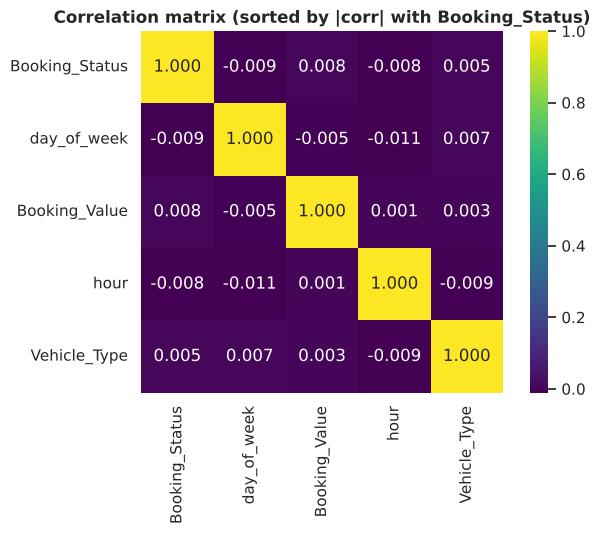

Largest |correlation| of any feature with the outcome: 0.009


In [6]:
enc = clf_raw.copy()
enc['Booking_Status'] = enc['Booking_Status'].astype('category').cat.codes
for c in ['Vehicle_Type', 'day_of_week']:
    enc[c] = enc[c].astype('category').cat.codes
corr = enc.corr()
corr = corr.loc[corr['Booking_Status'].abs().sort_values(ascending=False).index, corr['Booking_Status'].abs().sort_values(ascending=False).index]
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='viridis', square=True)
plt.title('Correlation matrix (sorted by |corr| with Booking_Status)', fontweight='bold')
plt.tight_layout(); plt.show(); plt.close('all')
print("Largest |correlation| of any feature with the outcome: %.3f" % corr['Booking_Status'].drop('Booking_Status').abs().max())

**What the EDA tells us.** The classes are clearly imbalanced, and the feature–outcome relationships are very weak: the outcome mix is nearly the same for every vehicle type, weekday, hour and fare level. 
That is a property of the *data* (booking outcomes are driven by supply and demand, which are not recorded), not a bug in the code — and it sets the realistic expectation for every model below.

*Duplicates:* the few identical rows are kept — with only five low-cardinality columns, two different bookings can legitimately look the same.

## Section B — Preprocessing, Split and Baseline

### B1. Preprocessing pipeline

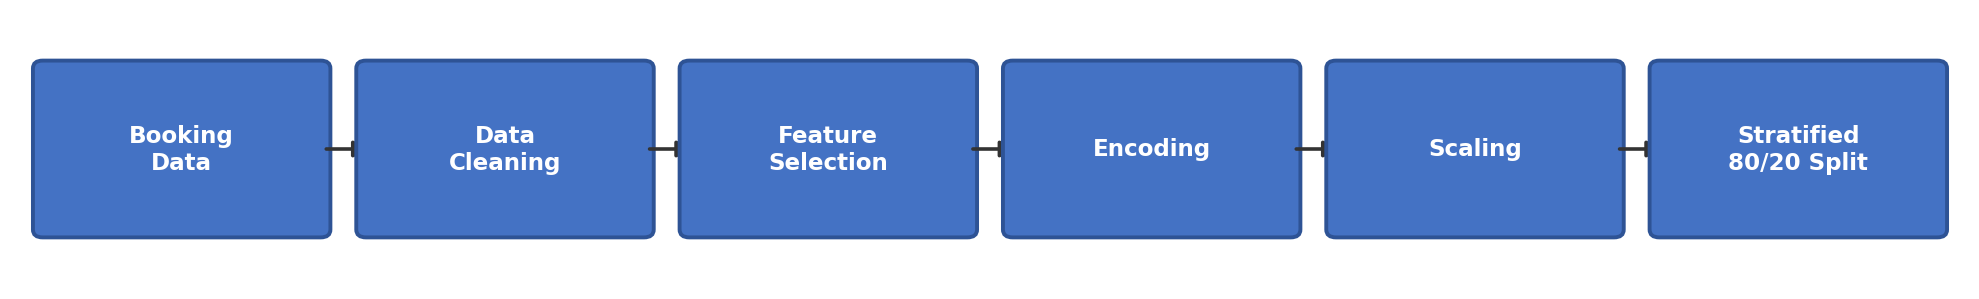

In [7]:
from IPython.display import Image, display
display(Image('pipeline_classification.png'))

**Leakage control.** Only information available *before* a booking resolves is used. Fields such as cancellation reasons, ride distance or ratings (which exist only after the outcome) were dropped in data preparation.
Scaling and one-hot encoding live **inside** the pipeline so they are fitted on training data only.

In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.pipeline import Pipeline

num_f = ['Booking_Value', 'hour']
cat_f = ['Vehicle_Type', 'day_of_week']
TARGET = 'Booking_Status'

X = clf_raw[num_f + cat_f]
y = clf_raw[TARGET]
CLASSES = sorted(y.unique())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

def make_preprocessor():
    # a FRESH transformer for every pipeline, so no two models share fitted state
    return ColumnTransformer([
        ('num', StandardScaler(), num_f),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_f),
    ])

print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nClass share in train vs test (stratified):")
display(pd.DataFrame({'train %': y_train.value_counts(normalize=True)*100, 'test %': y_test.value_counts(normalize=True)*100}).round(2))

Train: (8000, 4)  Test: (2000, 4)

Class share in train vs test (stratified):


,train %,test %
Booking_Status,,
Success,62.09,62.10
Canceled by Driver,18.42,18.45
Canceled by Customer,9.79,9.75
Driver Not Found,9.70,9.70


### B2. Majority-class baseline — the bar every model must beat

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
yp = dummy.predict(X_test)
baseline_row = {'Model': 'Majority-class baseline', 'Accuracy': accuracy_score(y_test, yp),
                'Precision': precision_score(y_test, yp, average='weighted', zero_division=0),
                'Recall': recall_score(y_test, yp, average='weighted', zero_division=0),
                'F1 (weighted)': f1_score(y_test, yp, average='weighted', zero_division=0),
                'F1 (macro)': f1_score(y_test, yp, average='macro', zero_division=0), 'ROC-AUC (OvR)': 0.5, 'Train time (s)': 0.0}
pd.DataFrame([baseline_row]).round(4)

,Model,Accuracy,Precision,Recall,F1 (weighted),F1 (macro),ROC-AUC (OvR),Train time (s)
0,Majority-class baseline,0.621,0.3856,0.621,0.4758,0.1915,0.5,0.0


A model that never predicts any cancellation gets 62 % *accuracy* but a low *macro-F1* (it scores 0 on three of the four classes); this is why we report weighted F1, macro-F1 and ROC-AUC alongside accuracy.

## Section C — The 10 Classification Algorithms (baseline)

One algorithm per cell, same split and same preprocessing. `evaluate_classifier` records every metric used in the comparison tables.

In [10]:
clf_results, fitted_clf = [], {}

def evaluate_classifier(name, model):
    pipe = Pipeline([('prep', make_preprocessor()), ('model', model)])
    t0 = time.time(); pipe.fit(X_train, y_train); fit_s = time.time() - t0
    yp = pipe.predict(X_test); proba = pipe.predict_proba(X_test)
    row = {'Model': name,
           'Accuracy': accuracy_score(y_test, yp),
           'Precision': precision_score(y_test, yp, average='weighted', zero_division=0),
           'Recall': recall_score(y_test, yp, average='weighted', zero_division=0),
           'F1 (weighted)': f1_score(y_test, yp, average='weighted', zero_division=0),
           'F1 (macro)': f1_score(y_test, yp, average='macro', zero_division=0),
           'ROC-AUC (OvR)': roc_auc_score(y_test, proba, multi_class='ovr', average='weighted', labels=pipe.classes_),
           'Train time (s)': fit_s}
    clf_results.append(row); fitted_clf[name] = pipe
    print(f"{name}: Acc={row['Accuracy']:.4f}  wF1={row['F1 (weighted)']:.4f}  macroF1={row['F1 (macro)']:.4f}  AUC={row['ROC-AUC (OvR)']:.4f}")
    return pipe

### Part A — algorithms 1–5 (evaluated in Review 1, retrained here on the identical split)

### Algorithm 1 — Logistic Regression
Models the log-odds of each class as a linear function of the features (multinomial / softmax for >2 classes) and predicts the class with the highest probability. Fast, interpretable and a strong linear baseline.

In [11]:
from sklearn.linear_model import LogisticRegression
lr_pipe = evaluate_classifier('Logistic Regression', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))

Logistic Regression: Acc=0.6210  wF1=0.4758  macroF1=0.1915  AUC=0.4908


In [12]:
# Interpreting the coefficients as odds ratios (multinomial: one coefficient row per class)
lr = lr_pipe.named_steps['model']
odds = pd.DataFrame(np.exp(lr.coef_).T, index=lr_pipe.named_steps['prep'].get_feature_names_out(), columns=lr.classes_)
display(odds.loc[['num__Booking_Value', 'num__hour']].round(3))
print("Odds ratio = multiplicative change in the odds of that class for +1 standard deviation of the feature.")
print("Values all close to 1.0 -> the numeric features barely move the odds of any outcome.")

,Canceled by Customer,Canceled by Driver,Driver Not Found,Success
num__Booking_Value,0.998,0.971,1.027,1.004
num__hour,0.989,1.041,0.979,0.991


Odds ratio = multiplicative change in the odds of that class for +1 standard deviation of the feature.
Values all close to 1.0 -> the numeric features barely move the odds of any outcome.


### Algorithm 2 — K-Nearest Neighbors
A lazy learner: a booking is assigned the majority outcome of its *k* most similar training bookings (Euclidean distance on scaled features). Scaling matters because distance mixes units.

In [13]:
from sklearn.neighbors import KNeighborsClassifier
_ = evaluate_classifier('K-Nearest Neighbors', KNeighborsClassifier(n_neighbors=7))

K-Nearest Neighbors: Acc=0.5540  wF1=0.4735  macroF1=0.2184  AUC=0.5022


### Algorithm 3 — Gaussian Naive Bayes
Applies Bayes' rule assuming features are conditionally independent given the class and (here) Gaussian. Extremely fast; the independence assumption is rarely exact, and one-hot columns are not Gaussian, so we treat it as a probabilistic baseline.

In [14]:
from sklearn.naive_bayes import GaussianNB
_ = evaluate_classifier('Naive Bayes (Gaussian)', GaussianNB())

Naive Bayes (Gaussian): Acc=0.6205  wF1=0.4766  macroF1=0.1940  AUC=0.4926


### Algorithm 4 — Decision Tree
Recursively splits the data on the feature/threshold that most reduces Gini impurity; each leaf predicts its majority class. Easy to explain visually (diagram below); prone to overfitting without depth limits.

In [15]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
dt_pipe = evaluate_classifier('Decision Tree', DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE))

Decision Tree: Acc=0.6010  wF1=0.4739  macroF1=0.1970  AUC=0.4858


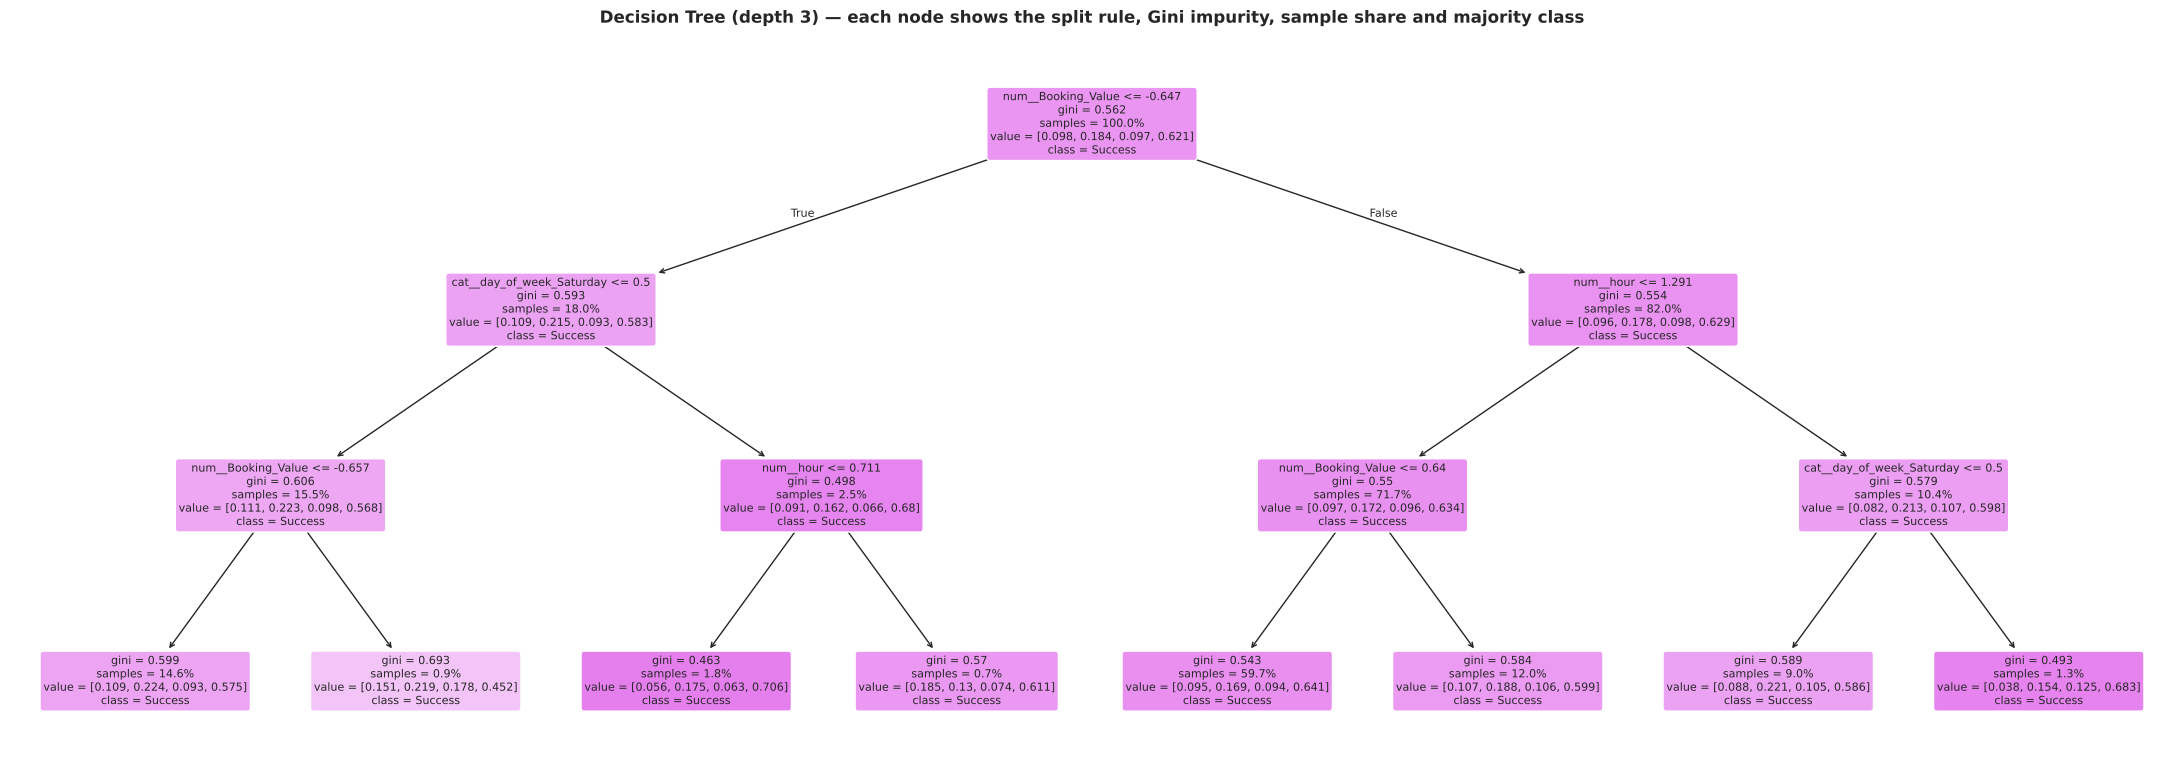

In [16]:
# How a decision tree works - a shallow depth-3 tree trained on the same preprocessed data
viz_prep = make_preprocessor()
Xtr_t = viz_prep.fit_transform(X_train)
viz_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=RANDOM_STATE).fit(Xtr_t, y_train)
plt.figure(figsize=(22, 8))
plot_tree(viz_tree, feature_names=viz_prep.get_feature_names_out(), class_names=list(viz_tree.classes_), filled=True, rounded=True, fontsize=8, proportion=True)
plt.title('Decision Tree (depth 3) — each node shows the split rule, Gini impurity, sample share and majority class', fontweight='bold')
plt.tight_layout(); plt.show(); plt.close('all')

### Algorithm 5 — Support Vector Machine (RBF kernel)
Finds the maximum-margin boundary between classes in a kernel-lifted feature space (one-vs-one for multi-class). `C` trades margin width against training errors. Sensitive to feature scale, hence the scaler.

In [17]:
from sklearn.svm import SVC
_ = evaluate_classifier('Support Vector Machine', SVC(kernel='rbf', C=5, probability=True, random_state=RANDOM_STATE))

Support Vector Machine: Acc=0.6170  wF1=0.4757  macroF1=0.1934  AUC=0.5051


### Part B — algorithms 6–10 (new in Review 2, same dataset, split and preprocessing as Part A)

### Algorithm 6 — Random Forest
An ensemble of decision trees, each trained on a bootstrap sample of rows with a random subset of features per split; the forest predicts by majority vote. Averaging many de-correlated trees reduces the variance of a single tree. `n_estimators` is tuned in Section D.

In [18]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier
rf_pipe = evaluate_classifier('Random Forest', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))

Random Forest: Acc=0.4935  wF1=0.4568  macroF1=0.2407  AUC=0.4939


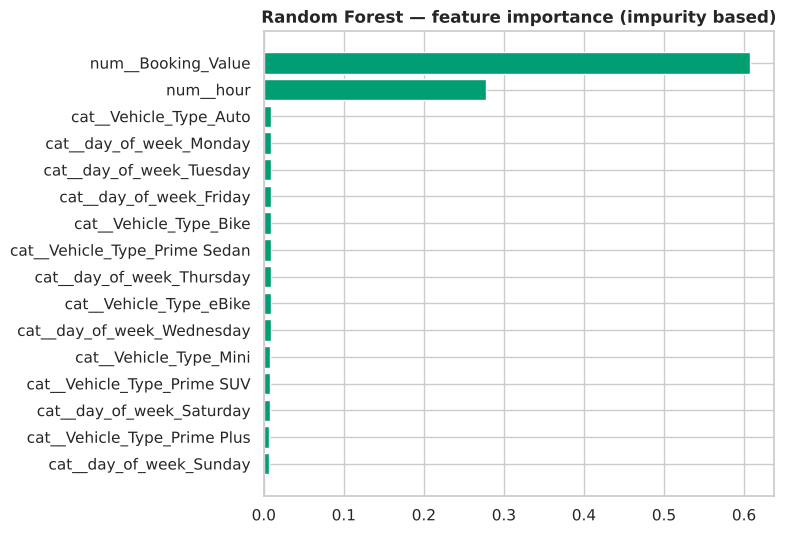

Top 3 features: num__Booking_Value, num__hour, cat__Vehicle_Type_Auto
Note: impurity importance favours continuous, high-cardinality features (Booking_Value, hour), so it is cross-checked with permutation importance in E6.


In [19]:
# Random Forest feature importance (mean decrease in impurity)
fi = pd.Series(rf_pipe.named_steps['model'].feature_importances_, index=rf_pipe.named_steps['prep'].get_feature_names_out()).sort_values()
plt.figure(figsize=(8, 5.5)); plt.barh(fi.index, fi.values, color=palette[2])
plt.title('Random Forest — feature importance (impurity based)', fontweight='bold'); plt.tight_layout(); plt.show(); plt.close('all')
print("Top 3 features:", ", ".join(fi.sort_values(ascending=False).index[:3]))
print("Note: impurity importance favours continuous, high-cardinality features (Booking_Value, hour), so it is cross-checked with permutation importance in E6.")

### Algorithm 7 — AdaBoost
Boosting with re-weighting: each new weak learner (a decision stump by default) focuses on the rows the previous learners misclassified; the final vote weights each learner by its accuracy. Tuned: `n_estimators` and `learning_rate`.

In [20]:
_ = evaluate_classifier('AdaBoost', AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE))

AdaBoost: Acc=0.6210  wF1=0.4758  macroF1=0.1915  AUC=0.4940


### Algorithm 8 — Gradient Boosting
Builds shallow trees sequentially, each one fitted to the gradient of the log-loss of the current ensemble (scikit-learn GBM). `learning_rate` shrinks each tree's contribution, trading speed for generalisation.

In [21]:
_ = evaluate_classifier('Gradient Boosting', GradientBoostingClassifier(random_state=RANDOM_STATE))

Gradient Boosting: Acc=0.6185  wF1=0.4767  macroF1=0.1950  AUC=0.4946


### Algorithm 9 — Bagging (Decision-Tree base estimator)
Bootstrap aggregating: trains many full decision trees on bootstrap samples and takes a majority vote. Unlike Random Forest it does not sub-sample features at each split, so its trees are more correlated.

In [22]:
_ = evaluate_classifier('Bagging', BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE), n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1))

Bagging: Acc=0.5460  wF1=0.4780  macroF1=0.2371  AUC=0.4928


### Algorithm 10 — MLP Classifier (neural network)
A feed-forward network: scaled inputs pass through hidden layers of neurons with non-linear activations, trained by back-propagation (Adam). `early_stopping` holds out 10 % of the training data to stop before overfitting. Tuned: `hidden_layer_sizes` and `activation`.

In [23]:
from sklearn.neural_network import MLPClassifier
_ = evaluate_classifier('MLP Neural Network', MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True, random_state=RANDOM_STATE))

MLP Neural Network: Acc=0.6210  wF1=0.4758  macroF1=0.1915  AUC=0.4990


### C11. Baseline comparison table — all 10 algorithms + majority baseline

In [24]:
base_df = pd.DataFrame([baseline_row] + clf_results).sort_values('F1 (weighted)', ascending=False).reset_index(drop=True)
base_df.index += 1
display(base_df.round(4))

,Model,Accuracy,Precision,Recall,F1 (weighted),F1 (macro),ROC-AUC (OvR),Train time (s)
1,Bagging,0.5460,0.4414,0.5460,0.4780,0.2371,0.4928,4.5113
2,Gradient Boosting,0.6185,0.4467,0.6185,0.4767,0.1950,0.4946,2.5134
3,Naive Bayes (Gaussian),0.6205,0.4100,0.6205,0.4766,0.1940,0.4926,0.0232
4,MLP Neural Network,0.6210,0.3856,0.6210,0.4758,0.1915,0.4990,0.8728
5,Logistic Regression,0.6210,0.3856,0.6210,0.4758,0.1915,0.4908,0.0432
6,Majority-class baseline,0.6210,0.3856,0.6210,0.4758,0.1915,0.5000,0.0000
7,AdaBoost,0.6210,0.3856,0.6210,0.4758,0.1915,0.4940,1.3696
8,Support Vector Machine,0.6170,0.4463,0.6170,0.4757,0.1934,0.5051,40.5238
9,Decision Tree,0.6010,0.4132,0.6010,0.4739,0.1970,0.4858,0.0315
10,K-Nearest Neighbors,0.5540,0.4286,0.5540,0.4735,0.2184,0.5022,0.0220


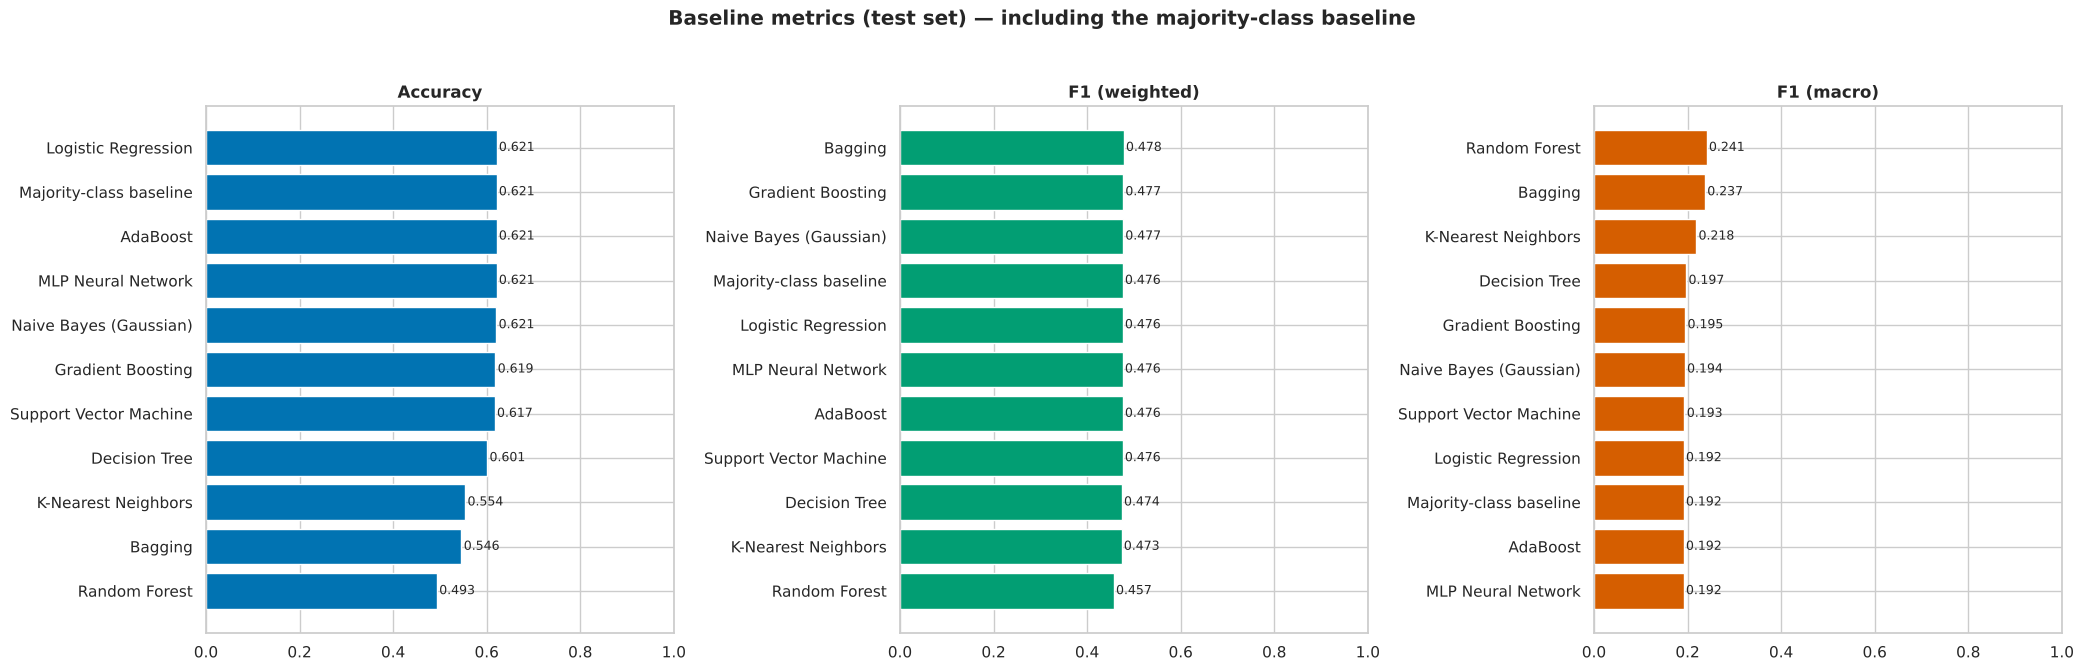

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
plot_df = base_df.set_index('Model')
for ax, (m, col) in zip(axes, [('Accuracy', palette[0]), ('F1 (weighted)', palette[2]), ('F1 (macro)', palette[3])]):
    s = plot_df[m].sort_values()
    ax.barh(s.index, s.values, color=col)
    for i, v in enumerate(s.values): ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=9)
    ax.set_xlim(0, max(1.0, s.max()*1.15)); ax.set_title(m, fontweight='bold')
plt.suptitle('Baseline metrics (test set) — including the majority-class baseline', fontweight='bold', y=1.03)
plt.tight_layout(); plt.show(); plt.close('all')

### C12. Cross-validation (5-fold, stratified) — all 10 algorithms

,Model,CV weighted F1 (mean),CV std
1,K-Nearest Neighbors,0.4787,0.0019
2,Decision Tree,0.4779,0.0036
3,Support Vector Machine,0.4775,0.0012
4,Gradient Boosting,0.4768,0.0023
5,Naive Bayes (Gaussian),0.4757,0.0009
6,Logistic Regression,0.4757,0.0004
7,MLP Neural Network,0.4757,0.0004
8,AdaBoost,0.4756,0.0004
9,Bagging,0.4747,0.0074
10,Random Forest,0.4722,0.0086


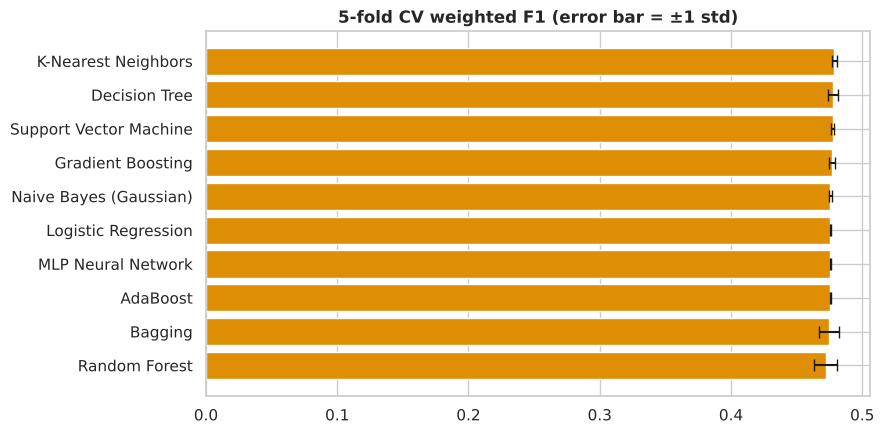

In [26]:
from sklearn.base import clone
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name in fitted_clf:
    pipe = Pipeline([('prep', make_preprocessor()), ('model', clone(fitted_clf[name].named_steps['model']))])
    if isinstance(pipe.named_steps['model'], SVC): pipe.set_params(model__probability=False)   # labels only -> faster
    sc = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1_weighted', n_jobs=-1)
    cv_rows.append({'Model': name, 'CV weighted F1 (mean)': sc.mean(), 'CV std': sc.std()})
cv_df = pd.DataFrame(cv_rows).sort_values('CV weighted F1 (mean)', ascending=False).reset_index(drop=True)
cv_df.index += 1
display(cv_df.round(4))
plt.figure(figsize=(9, 4.5))
plt.barh(cv_df['Model'][::-1], cv_df['CV weighted F1 (mean)'][::-1], xerr=cv_df['CV std'][::-1], color=palette[1], capsize=4)
plt.title('5-fold CV weighted F1 (error bar = ±1 std)', fontweight='bold'); plt.tight_layout(); plt.show(); plt.close('all')

## Section D — Hyperparameter Tuning (GridSearchCV, scored on weighted F1)

In [27]:
tuned_results, tuned_models = [], {}

from sklearn.base import clone
from sklearn.svm import SVC

def fast(est):
    # F1-based CV needs only hard labels, so SVM probability calibration is switched off there (same predictions logic, ~5x faster)
    est = clone(est)
    if isinstance(est.named_steps['model'], SVC):
        est.set_params(model__probability=False)
    return est

def tune_classifier(name, estimator, param_grid):
    pipe = Pipeline([('prep', make_preprocessor()), ('model', estimator)])
    gs = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                      scoring='f1_weighted', n_jobs=-1, refit=True)
    t0 = time.time(); gs.fit(X_train, y_train); secs = time.time() - t0
    best = gs.best_estimator_
    if isinstance(best.named_steps['model'], SVC) and not best.named_steps['model'].probability:
        # grid search ran without Platt calibration (5x faster); refit the winner once with probabilities for ROC-AUC
        best = clone(best).set_params(model__probability=True).fit(X_train, y_train)
    yp = best.predict(X_test); proba = best.predict_proba(X_test)
    base_f1 = next(r['F1 (weighted)'] for r in clf_results if r['Model'] == name)
    row = {'Model': name, 'Best parameters': {k.replace('model__', ''): v for k, v in gs.best_params_.items()},
           'Baseline F1': base_f1, 'Tuned F1': f1_score(y_test, yp, average='weighted', zero_division=0),
           'Accuracy': accuracy_score(y_test, yp), 'Precision': precision_score(y_test, yp, average='weighted', zero_division=0),
           'Recall': recall_score(y_test, yp, average='weighted', zero_division=0),
           'F1 (macro)': f1_score(y_test, yp, average='macro', zero_division=0),
           'ROC-AUC (OvR)': roc_auc_score(y_test, proba, multi_class='ovr', average='weighted', labels=best.classes_),
           'CV F1': gs.best_score_, 'Search time (s)': secs}
    row['Change'] = row['Tuned F1'] - base_f1
    tuned_results.append(row); tuned_models[name] = best
    print(f"{name}\n  best params : {row['Best parameters']}\n  baseline wF1 -> tuned wF1 : {base_f1:.4f} -> {row['Tuned F1']:.4f}   (CV wF1 {gs.best_score_:.4f})")
    return gs

#### Logistic Regression — regularisation strength `C`

In [28]:
gs_lr = tune_classifier('Logistic Regression', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                        {'model__C': [0.001, 0.01, 0.1, 1, 10, 100]})

Logistic Regression
  best params : {'C': 0.001}
  baseline wF1 -> tuned wF1 : 0.4758 -> 0.4758   (CV wF1 0.4757)


#### K-Nearest Neighbors — `k`, weighting and distance metric (Euclidean = straight-line, Manhattan = sum of absolute differences)

In [29]:
gs_knn = tune_classifier('K-Nearest Neighbors', KNeighborsClassifier(),
                         {'model__n_neighbors': [5, 11, 21, 31, 51, 101], 'model__weights': ['uniform', 'distance'], 'model__metric': ['euclidean', 'manhattan']})

K-Nearest Neighbors
  best params : {'metric': 'euclidean', 'n_neighbors': 31, 'weights': 'distance'}
  baseline wF1 -> tuned wF1 : 0.4735 -> 0.4833   (CV wF1 0.4821)


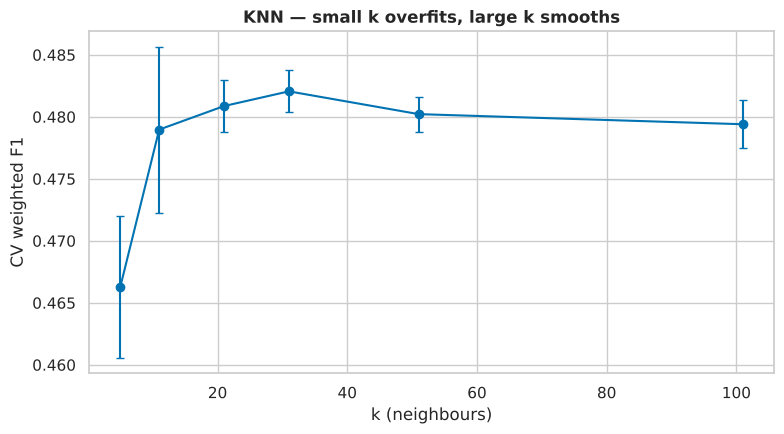

In [30]:
# Effect of k on CV score (bias-variance picture)
res = pd.DataFrame(gs_knn.cv_results_)
res = res[(res['param_model__weights'] == gs_knn.best_params_['model__weights']) & (res['param_model__metric'] == gs_knn.best_params_['model__metric'])]
plt.figure(figsize=(8, 4.5))
plt.errorbar(res['param_model__n_neighbors'].astype(int), res['mean_test_score'], yerr=res['std_test_score'], marker='o', color=palette[0], capsize=3)
plt.xlabel('k (neighbours)'); plt.ylabel('CV weighted F1'); plt.title('KNN — small k overfits, large k smooths', fontweight='bold')
plt.tight_layout(); plt.show(); plt.close('all')

#### Naive Bayes — `var_smoothing`

In [31]:
gs_nb = tune_classifier('Naive Bayes (Gaussian)', GaussianNB(), {'model__var_smoothing': np.logspace(-9, 0, 10)})

Naive Bayes (Gaussian)
  best params : {'var_smoothing': np.float64(0.01)}
  baseline wF1 -> tuned wF1 : 0.4766 -> 0.4771   (CV wF1 0.4758)


#### Decision Tree — depth and leaf size (controls overfitting)

In [32]:
gs_dt = tune_classifier('Decision Tree', DecisionTreeClassifier(random_state=RANDOM_STATE),
                        {'model__max_depth': [2, 3, 5, 8, 12], 'model__min_samples_leaf': [1, 10, 30, 100], 'model__criterion': ['gini', 'entropy']})

Decision Tree
  best params : {'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 10}
  baseline wF1 -> tuned wF1 : 0.4739 -> 0.4861   (CV wF1 0.4876)


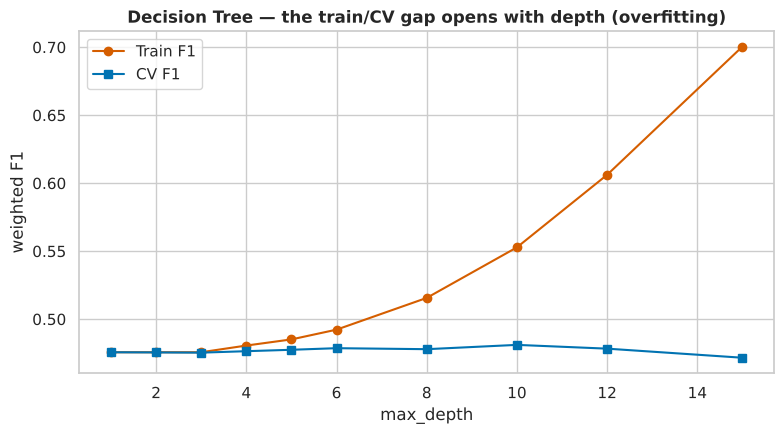

In [33]:
# Overfitting picture: train vs CV score as the tree gets deeper
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15]
tr, cv = [], []
for d in depths:
    p = Pipeline([('prep', make_preprocessor()), ('model', DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))])
    cv.append(cross_val_score(p, X_train, y_train, cv=skf, scoring='f1_weighted', n_jobs=-1).mean())
    tr.append(f1_score(y_train, p.fit(X_train, y_train).predict(X_train), average='weighted'))
plt.figure(figsize=(8, 4.5))
plt.plot(depths, tr, 'o-', label='Train F1', color=palette[3]); plt.plot(depths, cv, 's-', label='CV F1', color=palette[0])
plt.xlabel('max_depth'); plt.ylabel('weighted F1'); plt.legend(); plt.title('Decision Tree — the train/CV gap opens with depth (overfitting)', fontweight='bold')
plt.tight_layout(); plt.show(); plt.close('all')

#### SVM — `C` and `kernel`

In [34]:
gs_svm = tune_classifier('Support Vector Machine', SVC(kernel='rbf', probability=False, random_state=RANDOM_STATE),
                         {'model__C': [0.5, 1, 5], 'model__kernel': ['rbf', 'poly']})

Support Vector Machine
  best params : {'C': 5, 'kernel': 'rbf'}
  baseline wF1 -> tuned wF1 : 0.4757 -> 0.4757   (CV wF1 0.4775)


### Part B tuning

#### Random Forest — `n_estimators` and depth

In [35]:
gs_rf = tune_classifier('Random Forest', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                        {'model__n_estimators': [100, 300], 'model__max_depth': [None, 8, 16], 'model__min_samples_leaf': [1, 10]})

Random Forest
  best params : {'max_depth': 16, 'min_samples_leaf': 1, 'n_estimators': 100}
  baseline wF1 -> tuned wF1 : 0.4568 -> 0.4805   (CV wF1 0.4842)


#### AdaBoost — `n_estimators` and `learning_rate`

In [36]:
gs_ada = tune_classifier('AdaBoost', AdaBoostClassifier(random_state=RANDOM_STATE),
                         {'model__n_estimators': [50, 100, 200], 'model__learning_rate': [0.05, 0.5, 1.0]})

AdaBoost
  best params : {'learning_rate': 0.05, 'n_estimators': 50}
  baseline wF1 -> tuned wF1 : 0.4758 -> 0.4758   (CV wF1 0.4757)


#### Gradient Boosting — `learning_rate` and `n_estimators`

In [37]:
gs_gb = tune_classifier('Gradient Boosting', GradientBoostingClassifier(random_state=RANDOM_STATE),
                        {'model__n_estimators': [100, 200], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3]})

Gradient Boosting
  best params : {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
  baseline wF1 -> tuned wF1 : 0.4767 -> 0.4767   (CV wF1 0.4768)


#### Bagging — number of trees and bootstrap sample size

In [38]:
gs_bag = tune_classifier('Bagging', BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE), random_state=RANDOM_STATE, n_jobs=-1),
                         {'model__n_estimators': [50, 100], 'model__max_samples': [0.5, 1.0], 'model__estimator__max_depth': [None, 10]})

Bagging
  best params : {'estimator__max_depth': None, 'max_samples': 0.5, 'n_estimators': 50}
  baseline wF1 -> tuned wF1 : 0.4780 -> 0.4828   (CV wF1 0.4802)


#### MLP — `hidden_layer_sizes` and `activation`

In [39]:
gs_mlp = tune_classifier('MLP Neural Network', MLPClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
                         {'model__hidden_layer_sizes': [(32,), (64, 32), (128, 64)], 'model__activation': ['relu', 'tanh'], 'model__alpha': [1e-4, 1e-2]})

MLP Neural Network
  best params : {'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (32,)}
  baseline wF1 -> tuned wF1 : 0.4758 -> 0.4758   (CV wF1 0.4759)


### Tuning summary — before vs after

,Model,Best parameters,Baseline F1,Tuned F1,Change,CV F1
1,Decision Tree,"{'criterion': 'gini', 'max_depth': 12, 'min_sa...",0.4739,0.4861,0.0122,0.4876
2,K-Nearest Neighbors,"{'metric': 'euclidean', 'n_neighbors': 31, 'we...",0.4735,0.4833,0.0098,0.4821
3,Bagging,"{'estimator__max_depth': None, 'max_samples': ...",0.4780,0.4828,0.0048,0.4802
4,Random Forest,"{'max_depth': 16, 'min_samples_leaf': 1, 'n_es...",0.4568,0.4805,0.0237,0.4842
5,Naive Bayes (Gaussian),{'var_smoothing': 0.01},0.4766,0.4771,0.0005,0.4758
6,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.4767,0.4767,0.0000,0.4768
7,Logistic Regression,{'C': 0.001},0.4758,0.4758,0.0000,0.4757
8,AdaBoost,"{'learning_rate': 0.05, 'n_estimators': 50}",0.4758,0.4758,0.0000,0.4757
9,MLP Neural Network,"{'activation': 'tanh', 'alpha': 0.0001, 'hidde...",0.4758,0.4758,0.0000,0.4759
10,Support Vector Machine,"{'C': 5, 'kernel': 'rbf'}",0.4757,0.4757,0.0000,0.4775


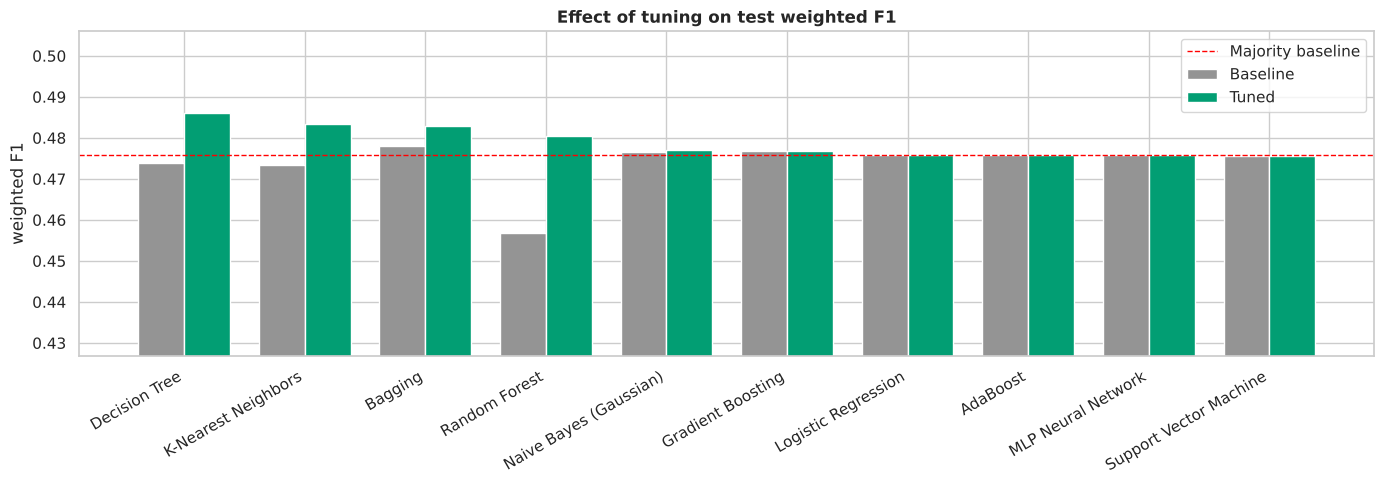

Documented improvement: tuning raised Random Forest weighted F1 from 0.4568 to 0.4805 (+0.0237).
Models improved by tuning: 4 of 10


In [40]:
tuned_df = pd.DataFrame(tuned_results).sort_values('Tuned F1', ascending=False).reset_index(drop=True)
tuned_df.index += 1
display(tuned_df[['Model', 'Best parameters', 'Baseline F1', 'Tuned F1', 'Change', 'CV F1']].round(4))
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(tuned_df)); w = 0.38
ax.bar(x - w/2, tuned_df['Baseline F1'], w, label='Baseline', color=palette[7])
ax.bar(x + w/2, tuned_df['Tuned F1'], w, label='Tuned', color=palette[2])
ax.axhline(baseline_row['F1 (weighted)'], color='red', ls='--', lw=1, label='Majority baseline')
ax.set_xticks(x); ax.set_xticklabels(tuned_df['Model'], rotation=30, ha='right'); ax.set_ylabel('weighted F1'); ax.legend()
ax.set_title('Effect of tuning on test weighted F1', fontweight='bold')
ax.set_ylim(tuned_df[['Baseline F1', 'Tuned F1']].values.min() - 0.03, tuned_df[['Baseline F1', 'Tuned F1']].values.max() + 0.02)
plt.tight_layout(); plt.show(); plt.close('all')
g = tuned_df.sort_values('Change', ascending=False).iloc[0]
print(f"Documented improvement: tuning raised {g['Model']} weighted F1 from {g['Baseline F1']:.4f} to {g['Tuned F1']:.4f} ({g['Change']:+.4f}).")
print(f"Models improved by tuning: {(tuned_df['Change'] > 0.0005).sum()} of {len(tuned_df)}")

## Section E — Final Comparison, Diagnostics, Best-Model Selection

### E1. Consolidated comparison table — all 10 classification algorithms (tuned) + majority baseline

In [41]:
final_df = tuned_df[['Model', 'Accuracy', 'Precision', 'Recall', 'Tuned F1', 'F1 (macro)', 'ROC-AUC (OvR)', 'CV F1']].rename(columns={'Tuned F1': 'F1 (weighted)'})
final_df = pd.concat([pd.DataFrame([baseline_row]).drop(columns=['Train time (s)']).assign(**{'CV F1': np.nan}), final_df]).sort_values('F1 (weighted)', ascending=False).reset_index(drop=True)
final_df.index += 1
display(final_df.round(4))

,Model,Accuracy,Precision,Recall,F1 (weighted),F1 (macro),ROC-AUC (OvR),CV F1
1,Decision Tree,0.5815,0.4567,0.5815,0.4861,0.2286,0.4797,0.4876
2,K-Nearest Neighbors,0.5855,0.4442,0.5855,0.4833,0.2220,0.4968,0.4821
3,Bagging,0.5850,0.4471,0.5850,0.4828,0.2230,0.4866,0.4802
4,Random Forest,0.5725,0.4421,0.5725,0.4805,0.2262,0.4974,0.4842
5,Naive Bayes (Gaussian),0.6215,0.4345,0.6215,0.4771,0.1942,0.4926,0.4758
6,Gradient Boosting,0.6185,0.4467,0.6185,0.4767,0.1950,0.4946,0.4768
7,Majority-class baseline,0.6210,0.3856,0.6210,0.4758,0.1915,0.5000,NaN
8,Logistic Regression,0.6210,0.3856,0.6210,0.4758,0.1915,0.4909,0.4757
9,AdaBoost,0.6210,0.3856,0.6210,0.4758,0.1915,0.4902,0.4757
10,MLP Neural Network,0.6210,0.3856,0.6210,0.4758,0.1915,0.5036,0.4759


### E2. Confusion matrices — all 10 tuned models

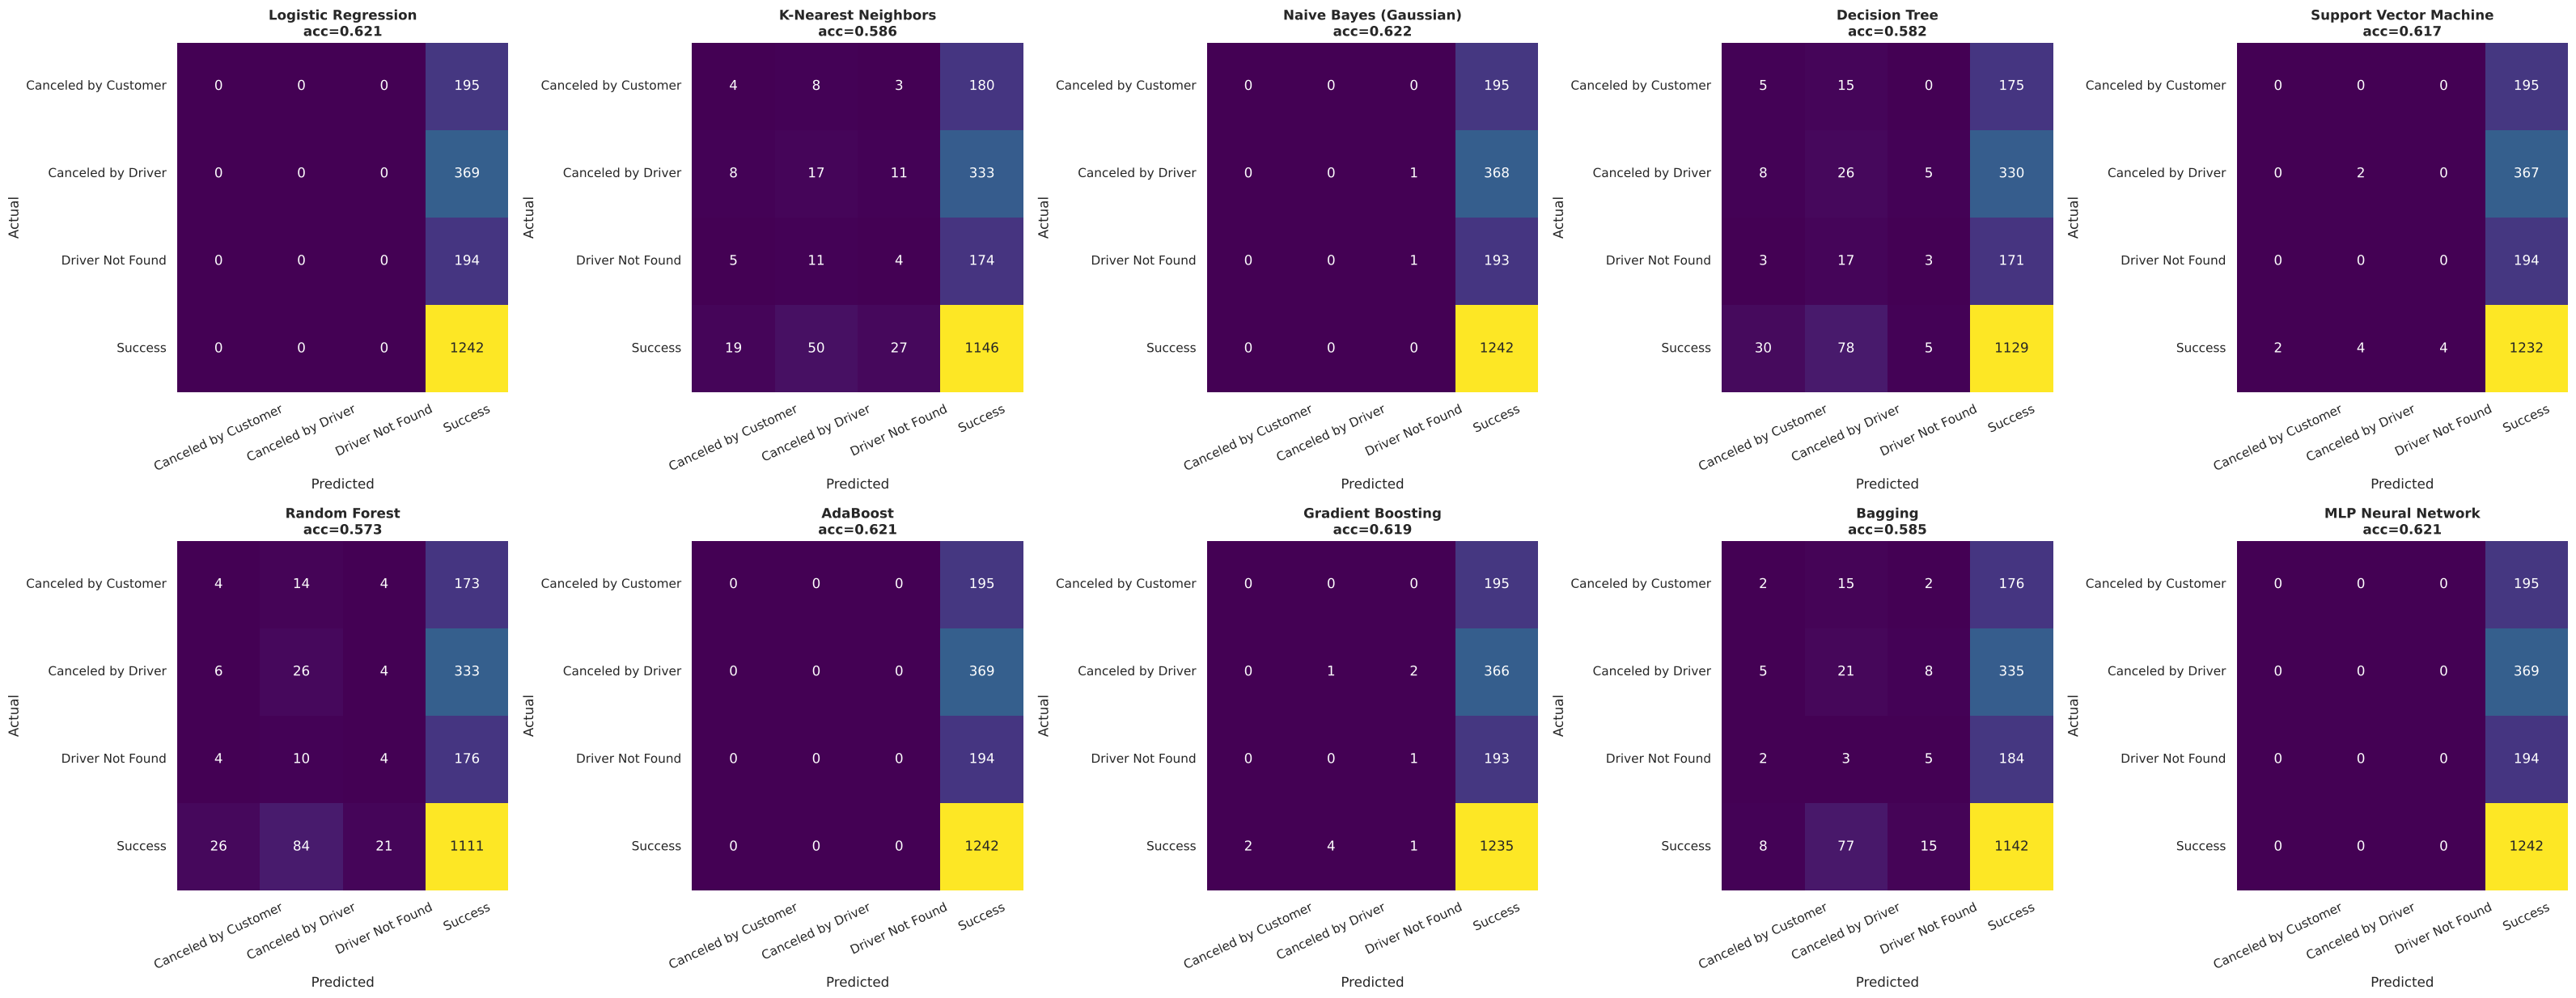

In [42]:
fig, axes = plt.subplots(2, 5, figsize=(32, 12.5))
for ax, (name, pipe) in zip(axes.ravel(), tuned_models.items()):
    yp = pipe.predict(X_test)
    cm = confusion_matrix(y_test, yp, labels=CLASSES)
    sns.heatmap(cm, annot=True, fmt='d', cmap='viridis', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False)
    ax.set_title(f"{name}\nacc={accuracy_score(y_test, yp):.3f}", fontweight='bold'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.tick_params(axis='x', rotation=25)
for ax in axes.ravel()[len(tuned_models):]: ax.axis('off')
plt.tight_layout(); plt.show(); plt.close('all')

### E3. ROC curves (one-vs-rest) — micro-view per class for each tuned model

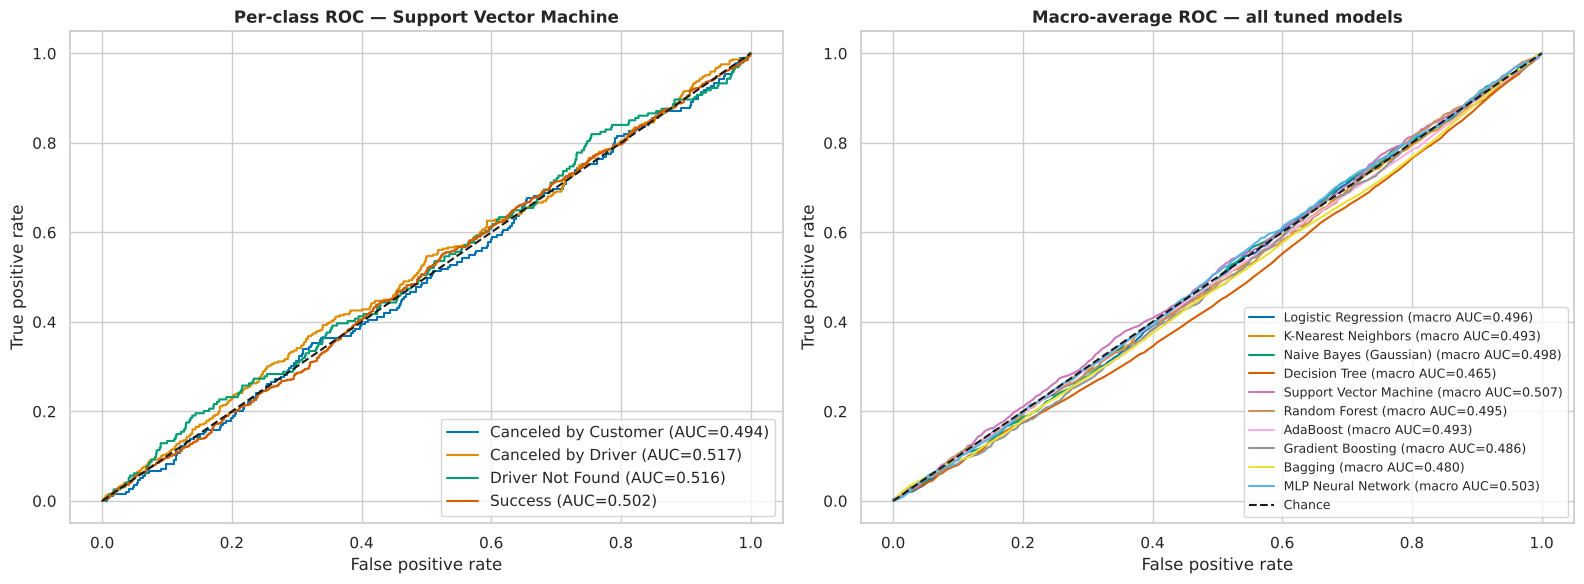

In [43]:
from sklearn.metrics import roc_curve, auc
Yb = label_binarize(y_test, classes=CLASSES)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# (left) per-class ROC of the best-by-AUC model; (right) macro one-vs-rest ROC of every model
best_auc_name = max(tuned_models, key=lambda n: roc_auc_score(y_test, tuned_models[n].predict_proba(X_test), multi_class='ovr', labels=CLASSES))
P = tuned_models[best_auc_name].predict_proba(X_test)
for i, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(Yb[:, i], P[:, i]); axes[0].plot(fpr, tpr, color=palette[i], label=f'{c} (AUC={auc(fpr, tpr):.3f})')
axes[0].plot([0,1],[0,1],'k--'); axes[0].set_title(f'Per-class ROC — {best_auc_name}', fontweight='bold'); axes[0].legend(loc='lower right')
for j, (name, pipe) in enumerate(tuned_models.items()):
    P = pipe.predict_proba(X_test)
    grid = np.linspace(0, 1, 200); tprs = []
    for i in range(len(CLASSES)):
        fpr, tpr, _ = roc_curve(Yb[:, i], P[:, i]); tprs.append(np.interp(grid, fpr, tpr))
    m = np.mean(tprs, axis=0); axes[1].plot(grid, m, color=palette[j], label=f'{name} (macro AUC={auc(grid, m):.3f})')
axes[1].plot([0,1],[0,1],'k--', label='Chance'); axes[1].set_title('Macro-average ROC — all tuned models', fontweight='bold'); axes[1].legend(loc='lower right', fontsize=9)
for a in axes: a.set_xlabel('False positive rate'); a.set_ylabel('True positive rate')
plt.tight_layout(); plt.show(); plt.close('all')

### E4. Best-model selection (rule declared before looking at the test set)

In [44]:
# Stage 0: shortlist the 5 best models by their GridSearch 5-fold CV F1 (training data only).
# Stage 1: repeated stratified CV on TRAIN data (5 folds x 3 repeats). Stage 2: models within 0.005 of the top CV score -> highest test weighted F1.
shortlist = tuned_df.sort_values('CV F1', ascending=False).head(5)['Model'].tolist()
print("Shortlist (top 5 by GridSearch CV F1):", ", ".join(shortlist))
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
rows = []
for name in shortlist:
    pipe = tuned_models[name]
    sc = cross_val_score(fast(pipe), X_train, y_train, cv=rskf, scoring='f1_weighted', n_jobs=-1)
    rows.append({'Model': name, 'Repeated-CV F1': sc.mean(), 'std': sc.std(),
                 'Test F1': tuned_df.set_index('Model').loc[name, 'Tuned F1']})
sel = pd.DataFrame(rows).sort_values('Repeated-CV F1', ascending=False).reset_index(drop=True)
top = sel['Repeated-CV F1'].max()
sel['In tie group'] = sel['Repeated-CV F1'] >= top - 0.005
display(sel.round(4))
best_clf_name = sel[sel['In tie group']].sort_values('Test F1', ascending=False).iloc[0]['Model']
best_clf = tuned_models[best_clf_name]
print(f"\nSelected model: {best_clf_name}")
print(f"Tie group (within 0.005 of best CV): {', '.join(sel[sel['In tie group']]['Model'])}")

Shortlist (top 5 by GridSearch CV F1): Decision Tree, Random Forest, K-Nearest Neighbors, Bagging, Support Vector Machine


,Model,Repeated-CV F1,std,Test F1,In tie group
0,Decision Tree,0.4842,0.0053,0.4861,True
1,Random Forest,0.4822,0.0053,0.4805,True
2,K-Nearest Neighbors,0.4798,0.0042,0.4833,True
3,Bagging,0.4797,0.0055,0.4828,True
4,Support Vector Machine,0.4770,0.0019,0.4757,False



Selected model: Decision Tree
Tie group (within 0.005 of best CV): Decision Tree, Random Forest, K-Nearest Neighbors, Bagging


In [45]:
yp = best_clf.predict(X_test)
print(classification_report(y_test, yp, zero_division=0))
b = tuned_df.set_index('Model').loc[best_clf_name]
print(f"Best model accuracy {b['Accuracy']:.4f} vs majority baseline {MAJ:.4f}  -> lift {(b['Accuracy']-MAJ)*100:+.2f} percentage points")
print(f"Best model weighted F1 {b['Tuned F1']:.4f} vs majority baseline {baseline_row['F1 (weighted)']:.4f}")
print(f"Best model macro-F1    {b['F1 (macro)']:.4f} vs majority baseline {baseline_row['F1 (macro)']:.4f}")

                      precision    recall  f1-score   support

Canceled by Customer       0.11      0.03      0.04       195
  Canceled by Driver       0.19      0.07      0.10       369
    Driver Not Found       0.23      0.02      0.03       194
             Success       0.63      0.91      0.74      1242

            accuracy                           0.58      2000
           macro avg       0.29      0.26      0.23      2000
        weighted avg       0.46      0.58      0.49      2000

Best model accuracy 0.5815 vs majority baseline 0.6209  -> lift -3.94 percentage points
Best model weighted F1 0.4861 vs majority baseline 0.4758
Best model macro-F1    0.2286 vs majority baseline 0.1915


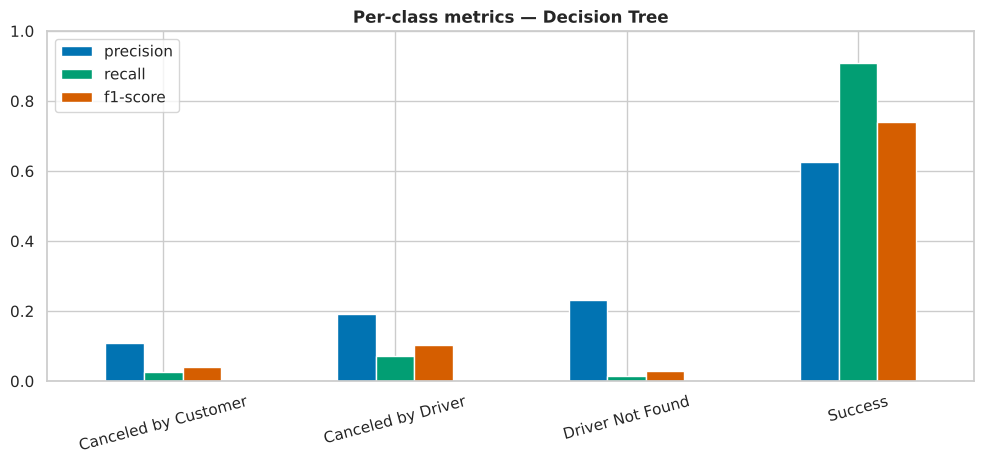

In [46]:
# Per-class precision / recall / F1 of the selected model
rep = pd.DataFrame(classification_report(y_test, yp, output_dict=True, zero_division=0)).T.loc[CLASSES, ['precision', 'recall', 'f1-score']]
rep.plot(kind='bar', figsize=(10, 4.8), color=[palette[0], palette[2], palette[3]])
plt.title(f'Per-class metrics — {best_clf_name}', fontweight='bold'); plt.xticks(rotation=15); plt.ylim(0, 1); plt.tight_layout(); plt.show(); plt.close('all')

### E5. Interpretation — why the scores are what they are
- Every model is compared with the **majority-class baseline**; the three "vs majority baseline" lines above show exactly how the selected model differs from always predicting *Success*. A model can gain weighted / macro F1 by *attempting* to predict cancellations, and lose accuracy at the same time if most of those attempts are wrong — so all three numbers are reported together.
- ROC-AUC values of all models sit at about 0.5, i.e. chance level. Together with the EDA (max |correlation| with the outcome ≈ 0.01, near-identical outcome mix across vehicle types, hours, weekdays and fares) this shows the features carry essentially **no information** about whether a booking succeeds.
- Model choice therefore follows the pre-declared rule on **cross-validated weighted F1** (the Review 1 metric); the honest conclusion is that *no* algorithm meaningfully beats the class prior on this feature set.

### E6. Feature importance (permutation importance on the test set)

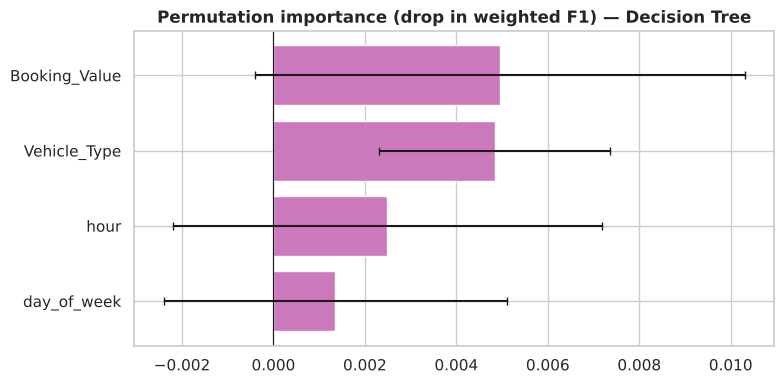

In [47]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(best_clf, X_test, y_test, scoring='f1_weighted', n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
plt.figure(figsize=(8, 4)); plt.barh(imp.index, imp.values, xerr=pi.importances_std[np.argsort(pi.importances_mean)], color=palette[4], capsize=3)
plt.axvline(0, color='k', lw=0.8); plt.title(f'Permutation importance (drop in weighted F1) — {best_clf_name}', fontweight='bold')
plt.tight_layout(); plt.show(); plt.close('all')

### E7. Export model, results and metadata (used by the web app)

In [48]:
joblib.dump(best_clf, '../models/best_classification_model.joblib')
final_df.round(4).to_csv('../models/classification_results.csv', index=False)
meta = {
    'best_model': best_clf_name,
    'classes': list(best_clf.classes_),
    'vehicle_types': sorted(clf_raw['Vehicle_Type'].unique().tolist()),
    'days': days,
    'booking_value_min': float(clf_raw['Booking_Value'].min()),
    'booking_value_max': float(clf_raw['Booking_Value'].max()),
    'booking_value_median': float(clf_raw['Booking_Value'].median()),
    'majority_baseline_accuracy': float(MAJ),
    'test_accuracy': float(b['Accuracy']), 'test_f1_weighted': float(b['Tuned F1']),
    'test_f1_macro': float(b['F1 (macro)']), 'test_roc_auc_ovr': float(b['ROC-AUC (OvR)']),
    'class_share': (y.value_counts(normalize=True)).round(4).to_dict(),
}
with open('../models/classification_meta.json', 'w') as f: json.dump(meta, f, indent=2)
# sanity: reload and predict one row
chk = joblib.load('../models/best_classification_model.joblib')
print(chk.predict_proba(X_test.iloc[[0]]).round(3), chk.classes_)
print("Saved model, results CSV and metadata to ../models/")

[[0.08  0.225 0.074 0.621]] ['Canceled by Customer' 'Canceled by Driver' 'Driver Not Found' 'Success']
Saved model, results CSV and metadata to ../models/


## Section F — Improvement Experiment: Handling the Class Imbalance

Accuracy rewards ignoring the minority classes. Here we test whether **class weighting** (`class_weight='balanced'`) changes how well the cancellation classes are detected, and what it costs in accuracy.

,Model,Setting,Accuracy,F1 (weighted),F1 (macro),Recall on minority classes
0,Logistic Regression,plain,0.6210,0.4758,0.1915,0.0000
1,Logistic Regression,class_weight=balanced,0.2390,0.2762,0.2018,0.2346
2,Decision Tree (depth 5),plain,0.6210,0.4758,0.1915,0.0000
3,Decision Tree (depth 5),class_weight=balanced,0.1095,0.0713,0.1179,0.3058


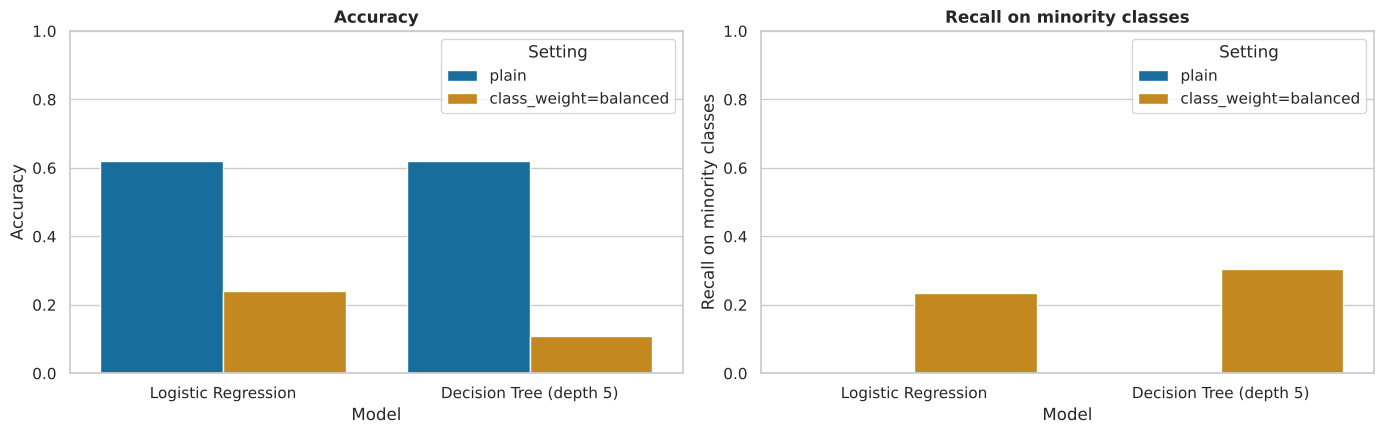

In [49]:
exp_models = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, C=1.0), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, C=1.0, class_weight='balanced')),
    'Decision Tree (depth 5)': (DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=RANDOM_STATE), DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, class_weight='balanced', random_state=RANDOM_STATE)),
}
rows = []
for name, (plain, bal) in exp_models.items():
    for tag, est in [('plain', plain), ('class_weight=balanced', bal)]:
        p = Pipeline([('prep', make_preprocessor()), ('model', est)]).fit(X_train, y_train)
        yp_ = p.predict(X_test)
        rows.append({'Model': name, 'Setting': tag, 'Accuracy': accuracy_score(y_test, yp_), 'F1 (weighted)': f1_score(y_test, yp_, average='weighted', zero_division=0),
                     'F1 (macro)': f1_score(y_test, yp_, average='macro', zero_division=0),
                     'Recall on minority classes': recall_score(y_test, yp_, labels=[c for c in CLASSES if c != 'Success'], average='macro', zero_division=0)})
exp_df = pd.DataFrame(rows); display(exp_df.round(4))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, m in zip(ax, ['Accuracy', 'Recall on minority classes']):
    sns.barplot(data=exp_df, x='Model', y=m, hue='Setting', palette=palette, ax=a); a.set_title(m, fontweight='bold'); a.set_ylim(0, 1)
plt.tight_layout(); plt.show(); plt.close('all')

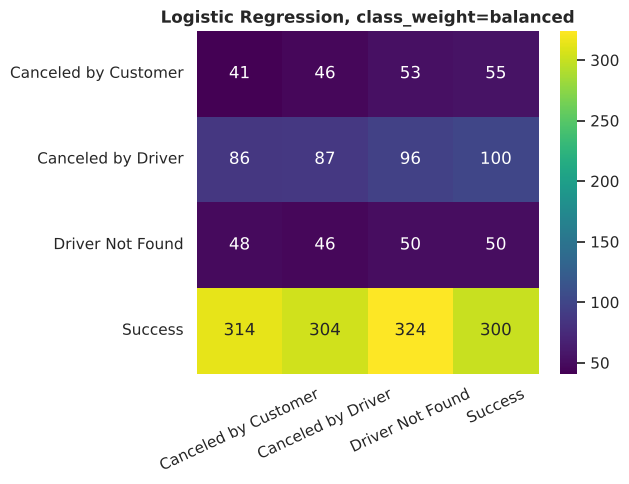

In [50]:
conf = confusion_matrix(y_test, Pipeline([('prep', make_preprocessor()), ('model', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE))]).fit(X_train, y_train).predict(X_test), labels=CLASSES)
plt.figure(figsize=(6.5, 5)); sns.heatmap(conf, annot=True, fmt='d', cmap='viridis', xticklabels=CLASSES, yticklabels=CLASSES)
plt.title('Logistic Regression, class_weight=balanced', fontweight='bold'); plt.xticks(rotation=25); plt.tight_layout(); plt.show(); plt.close('all')

**Reading the experiment.** Balanced weighting trades accuracy for minority-class recall: the model starts flagging cancellations, but because the features carry little signal it also raises many false alarms. 
Which setting is "better" is a business decision (is missing a cancellation costlier than a false alert?). For the deployed app we keep the CV-selected model above and report class probabilities, not just a hard label.

## Section G — Summary & Conclusion

In [51]:
print(f"Dataset              : {len(clf_raw):,} bookings, 4 outcome classes, majority class = {MAJ:.1%}")
print(f"Algorithms compared  : {len(tuned_models)} (Part A: 5, Part B: 5; baseline + GridSearch-tuned), plus a majority-class dummy")
print(f"Selected model       : {best_clf_name}")
print(f"  Accuracy {b['Accuracy']:.4f} | weighted F1 {b['Tuned F1']:.4f} | macro F1 {b['F1 (macro)']:.4f} | ROC-AUC {b['ROC-AUC (OvR)']:.4f}")
print(f"  Lift over majority baseline: {(b['Accuracy']-MAJ)*100:+.2f} pp accuracy")

Dataset              : 10,000 bookings, 4 outcome classes, majority class = 62.1%
Algorithms compared  : 10 (Part A: 5, Part B: 5; baseline + GridSearch-tuned), plus a majority-class dummy
Selected model       : Decision Tree
  Accuracy 0.5815 | weighted F1 0.4861 | macro F1 0.2286 | ROC-AUC 0.4797
  Lift over majority baseline: -3.94 pp accuracy


**Conclusions**
- All ten algorithms (Part A + Part B) land in a narrow band of weighted F1 with ROC-AUC close to 0.5 (see the consolidated table). Ensembles and the neural network do **not** escape this: with a 62 % majority class and features that carry almost no signal, the class prior dominates, not the algorithm.
- The final model was chosen by a pre-declared, cross-validated rule; its trade-off against the always-*Success* baseline (accuracy vs. weighted / macro F1) is printed in E4 and reported rather than hidden.
- Best practice here is to read results through the baseline, macro-F1 and ROC-AUC — not accuracy alone.
- **Limitations & future work:** adding supply-side information (driver availability, surge multiplier, pickup zone, weather) is the most promising way to move beyond the prior; cost-sensitive thresholds could then be tuned to the business cost of each cancellation type.